# EFA versus PCA: does changing the factor estimate help reversal?

October 29, 2026. **Result: no material improvement established.** EFA's later gross CAGR is 3.54% versus PCA's 3.37%; the paired daily mean difference is +0.065 bps, interval [−0.104,+0.263]. Future unexplained correlations and factor stability are almost unchanged. Reliable short-term reversal remains unconfirmed.

[Full intuitive findings](experiments/equity_efa_vs_pca/README.md) · [fixed specification](experiments/equity_efa_vs_pca/specification.json) · [source](experiments/equity_efa_vs_pca.py) · [running log](EQUITY_RESEARCH_LOG.md).

Same explicit SPY beta plus three additional factors, 120-session fit, signal, weighting, timing, and unit gross exposure. No TDA, gate, fees, factor-count search, or new download. These survivor stocks and historical dates have already been examined.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
cwd=Path.cwd()
candidates=[cwd,cwd/"TDA_Research",cwd/"Senior-Fall"/"TDA_Research",*cwd.parents]
project=next(p for p in candidates if (p/"START_HERE.md").is_file() and (p/"equity").is_dir())
out=project/"equity"/"experiments"/"equity_efa_vs_pca"
result=json.loads((out/"summary.json").read_text())
audit=json.loads((out/"independent_audit.json").read_text())
performance=pd.read_csv(out/"gross_performance.csv")
paired=pd.read_csv(out/"paired_comparisons.csv")
horizon=pd.read_csv(out/"horizon_summary.csv")
structural=pd.read_csv(out/"structural_summary.csv")
fitting=pd.read_csv(out/"fit_diagnostics.csv",parse_dates=["signal_date"])
assert all(result["checks"].values()) and all(audit["checks"].values())
print("Daily formations:",result["daily_dates"],"| periods:",result["daily_dates_by_period"])
print("Structural future blocks:",result["structural_blocks_by_period"])
print("EFA convergence iterations:",result["EFA_iterations"])
print("Local scikit-learn:",result["sklearn_version"])

Daily formations: 2446 | periods: {'development': 1738, 'later': 708}
Structural future blocks: {'development': 86, 'later': 35}
EFA convergence iterations: {'min': 6, 'median': 10.5, 'max': 77}
Local scikit-learn: 1.8.0


## 1. What changes between PCA and EFA?

PCA finds directions capturing observed variation. EFA fits a covariance model with common latent factors plus different stock-specific noise variances. It might distinguish common and individual movement differently. Neither approach makes the residual mean-reverting or discovers named economic causes automatically.

Both use the same daily admitted stocks, requiring 272 complete prior returns. Both fit SPY and standardize the previous 120 residual observations. PCA takes three leading directions; EFA estimates three loadings plus a separate unique variance for each stock. Exposure rows are multiplied by the residual standard deviations to restore raw-return units, then combined with dollar and SPY-beta columns.

The signal remains that day's adjusted close-close log return. We use the same cross-sectional WLS and inverse prior **total-return** variance weights. Holdings are **minus W times the WLS residual**, normalized to unit gross. EFA unique variances do not replace W, and EFA posterior scores do not become a different signal.

Positions remain dollar neutral and estimated-SPY/three-factor neutral at formation, enter next raw daily-bar open, and exit that close. Coefficient labels/signs are arbitrary; rotating a fixed factor span does not change these constraints. Exact settings are frozen, not chosen by profit.

In [2]:
print(result["configuration"]["EFA"])
print("Unique-variance minimum across all fits:",fitting.unique_variance_min.min())
print("Unique-variance maximum across all fits:",fitting.unique_variance_max.max())
period=np.where(fitting.signal_date.ge("2024-01-01"),"later","development")
display(fitting.assign(period=period).groupby("period")["PCA_EFA_raw_subspace_overlap"].agg(["mean","median","min","max"]).round(4))
print("Subspace overlap 1 means identical spans, even if factors are rotated or renamed.")

sklearn FactorAnalysis, three factors, lapack SVD, no rotation, tol0.001, max_iter1000, default all-ones unique variance initialization, no warm start or outcome-based model selection
Unique-variance minimum across all fits: 0.0481749477803964
Unique-variance maximum across all fits: 0.9916480793953744
Subspace overlap 1 means identical spans, even if factors are rotated or renamed.


,mean,median,min,max
period,,,,
development,0.962,0.9789,0.6644,0.9989
later,0.957,0.9704,0.6641,0.9965


## 2. Primary trading comparison: small difference, unresolved advantage

Every value is **gross/pre-fee**. Later means January 2024–October 27, 2026, with the same 708 executions as the original PCA run. The new PCA positions and point returns reproduce that run. Sixty-date paired block resamples acknowledge serial dependence; changing the seed changes interval endpoints, not the saved return series.

EFA later mean is +1.408 versus PCA +1.343 bps/day. The paired increment is only **+0.065 bps/day**, approximate95 interval **[−0.104,+0.263]**. CAGR changes from 3.37% to 3.54%, Sharpe from 0.89 to 0.93. Earlier, EFA is slightly worse. Both standalone means and both primary paired differences have intervals spanning zero.

The curves below start from the same capital separately in each period. They are the original daily portfolio without a learned on/off gate. A favorable point rank does not establish EFA superiority.

,period,model,days,mean_daily_bps,mean_low,mean_high,CAGR_percent,sharpe_vs_zero,mean_effective_breadth
0,development,PCA3,1738,-0.1254,-2.0507,1.9612,-0.3940,-0.0797,88.3017
1,development,EFA3,1738,-0.1655,-2.0889,1.9080,-0.4945,-0.1053,88.1235
2,later,PCA3,708,1.3427,-0.7643,3.3345,3.3666,0.8900,89.9545
3,later,EFA3,708,1.4079,-0.7030,3.3819,3.5360,0.9300,89.8748


,period,difference,point95_low,point95_high
0,development,-0.04009,-0.12577,0.03869
9,later,0.06517,-0.10393,0.26301


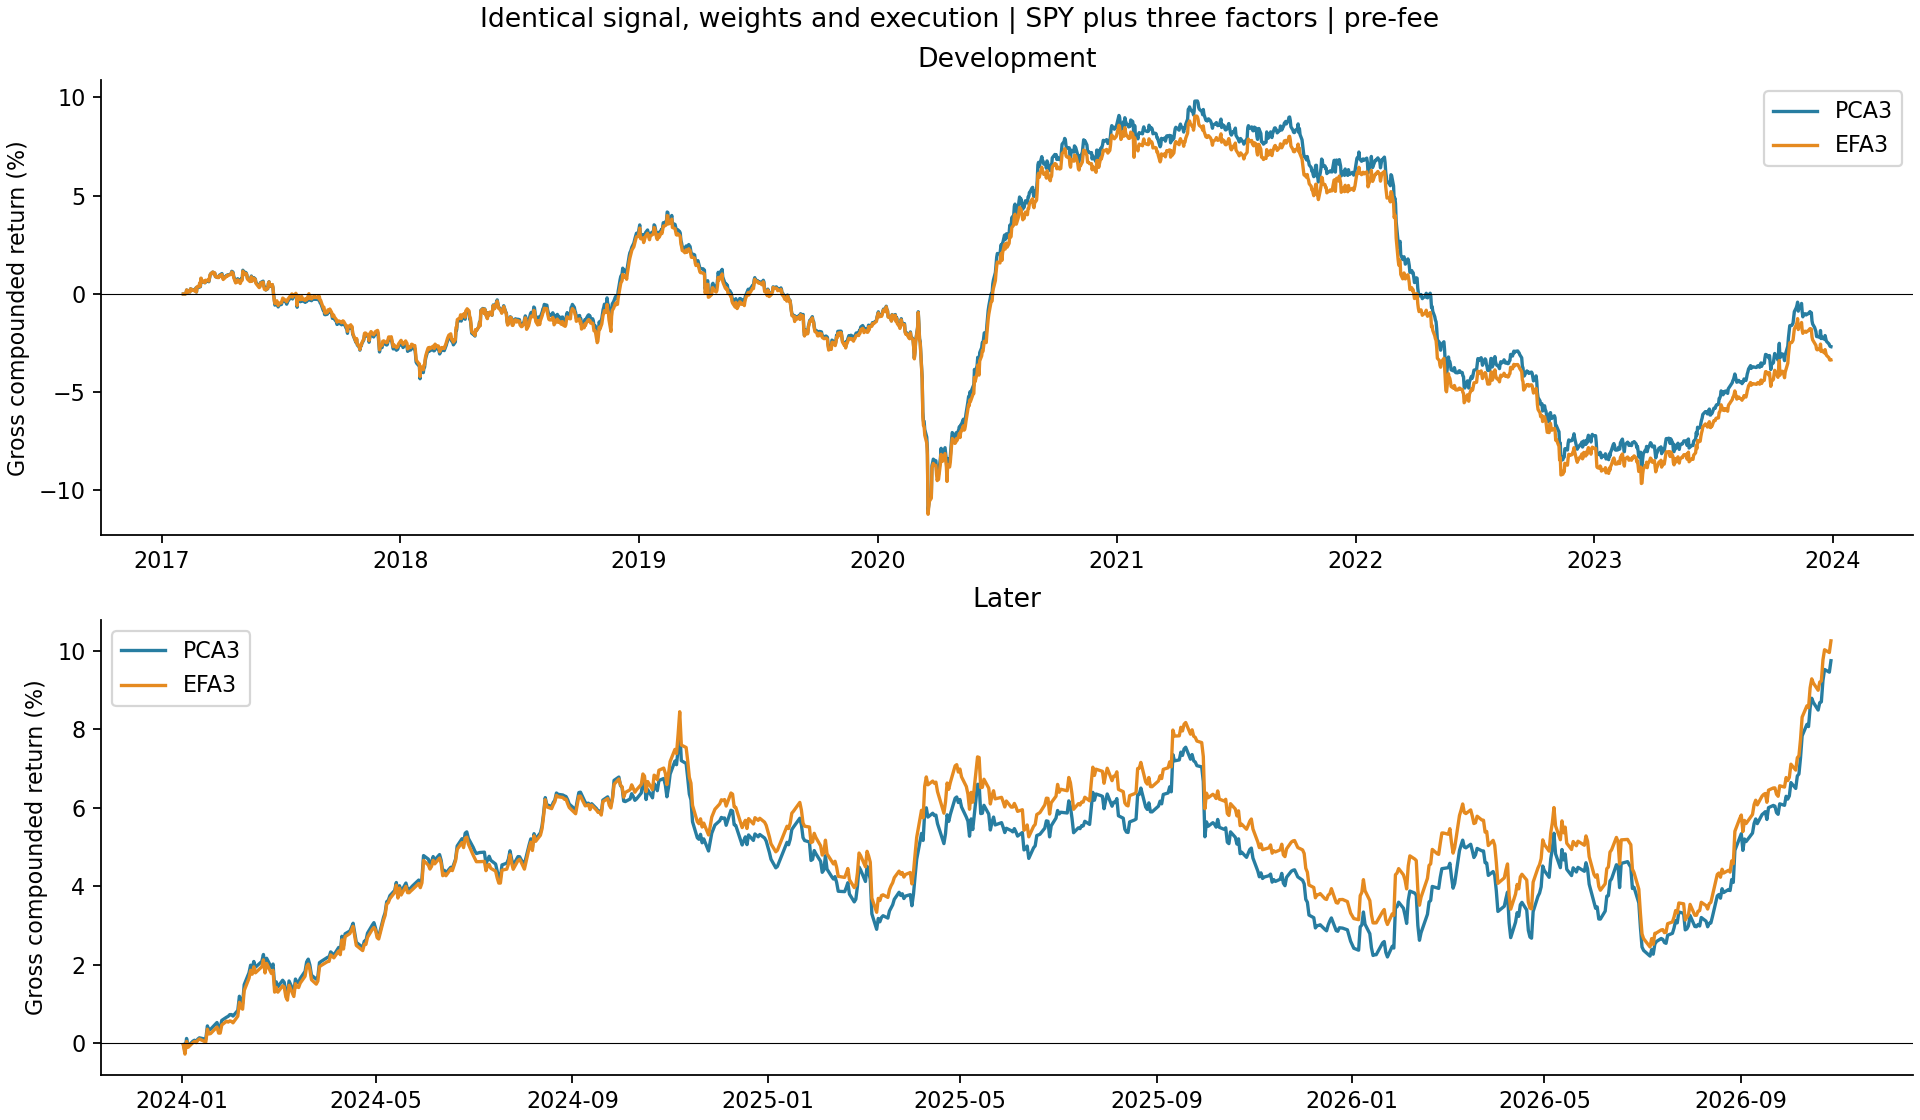

In [3]:
table=performance.copy()
table["CAGR_percent"]=table.gross_CAGR*100
display(table[["period","model","days","mean_daily_bps","mean_low","mean_high","CAGR_percent","sharpe_vs_zero","mean_effective_breadth"]].round(4))
display(paired.loc[paired.role.eq("primary"),["period","difference","point95_low","point95_high"]].round(5))
display(Image(filename=str(out/"01_gross_profit.png")))

## 3. Does EFA remove more future common movement or produce more stable factors?

Every twenty formation dates, freeze the past exposures and weights, then decompose the next twenty close-close return vectors by the same WLS. The average absolute residual correlation measures remaining pairwise co-movement. Future common-return coefficients are an **ex-post diagnostic**, never inputs to the trade. Those are WLS residuals, not directly EFA posterior unique errors.

For stability, compare the current three-column raw loading space with its previous diagnostic block on common stocks. The overlap ranges from zero to one and ignores arbitrary factor rotations/signs. Twenty future observations make individual correlations noisy, and overlapping estimation windows limit independent information.

Later absolute correlation is about **0.20614 PCA versus 0.20646 EFA**. Stability is **0.8765 versus 0.8802**. These differences are small; simultaneous paired intervals for both metrics span zero. Earlier EFA stability is slightly worse. Neither measure establishes a structural improvement or true economic factor identity.

,period,model,future_blocks,future_mean_abs_corr,future_RMS_corr,stability_blocks,mean_raw_subspace_stability
0,development,PCA3,86,0.205886,0.255465,85,0.886365
1,development,EFA3,86,0.205800,0.255363,85,0.875518
2,later,PCA3,35,0.206137,0.256403,35,0.876527
3,later,EFA3,35,0.206464,0.256750,35,0.880203


,period,metric,count,difference,sim95_low,sim95_high
7,development,future_abs_corr,85,-0.000073,-0.000350,0.000204
8,development,subspace_stability,85,-0.010846,-0.024713,0.003020
16,later,future_abs_corr,35,0.000328,-0.000893,0.001548
17,later,subspace_stability,35,0.003675,-0.013684,0.021035


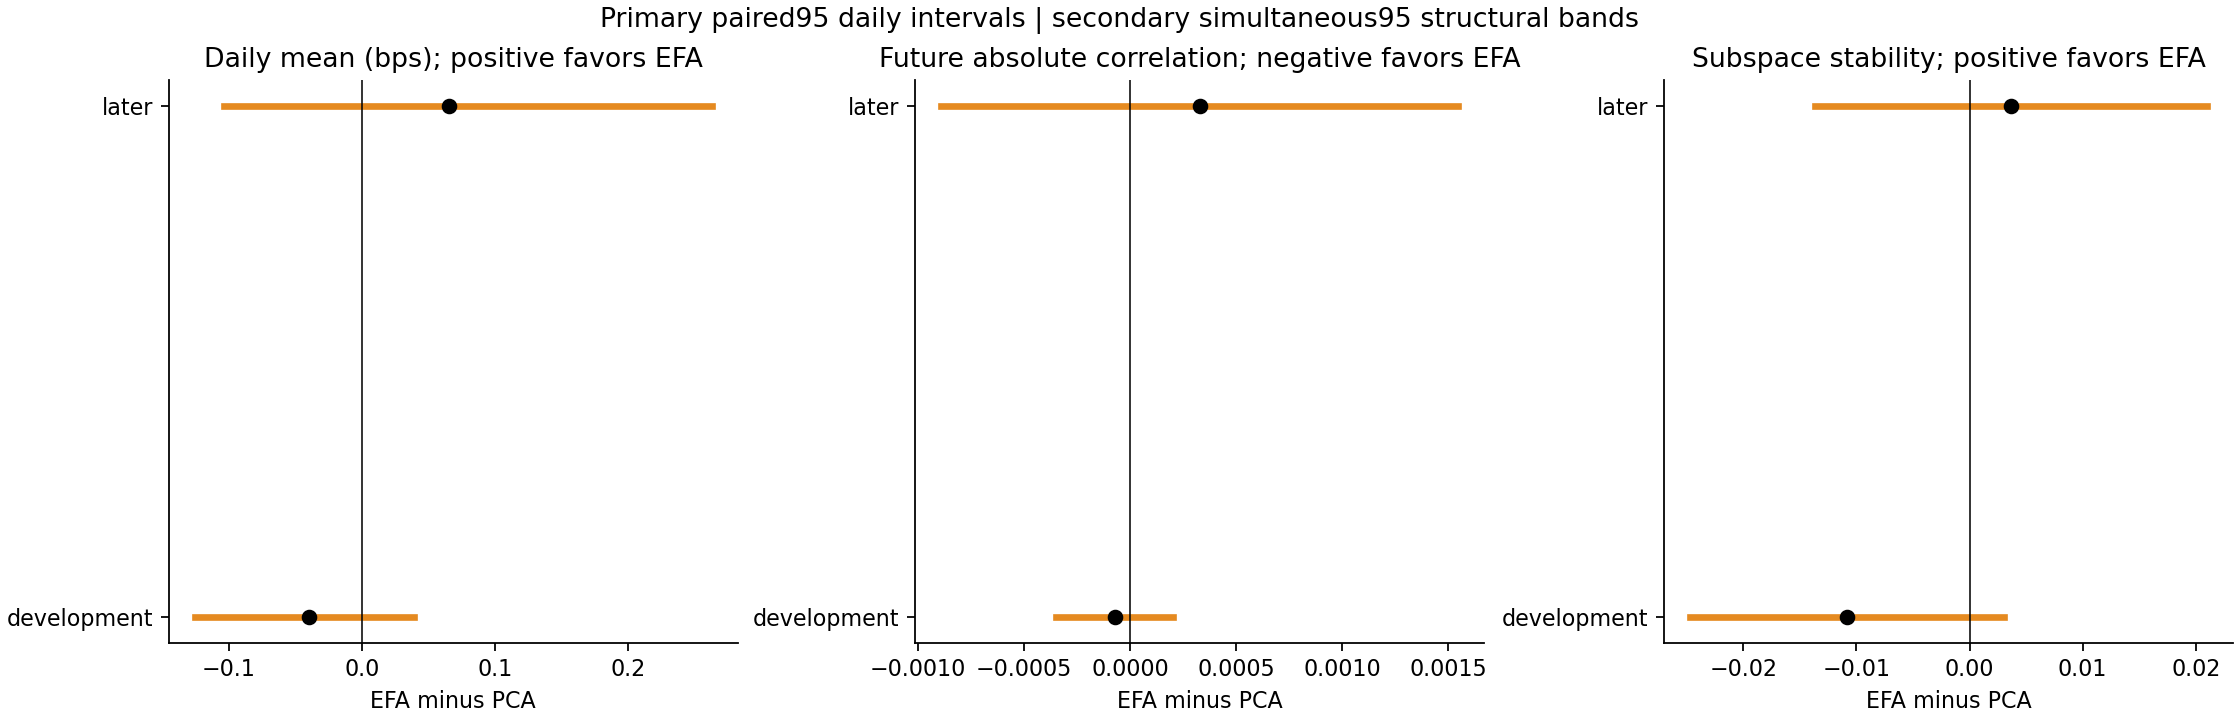

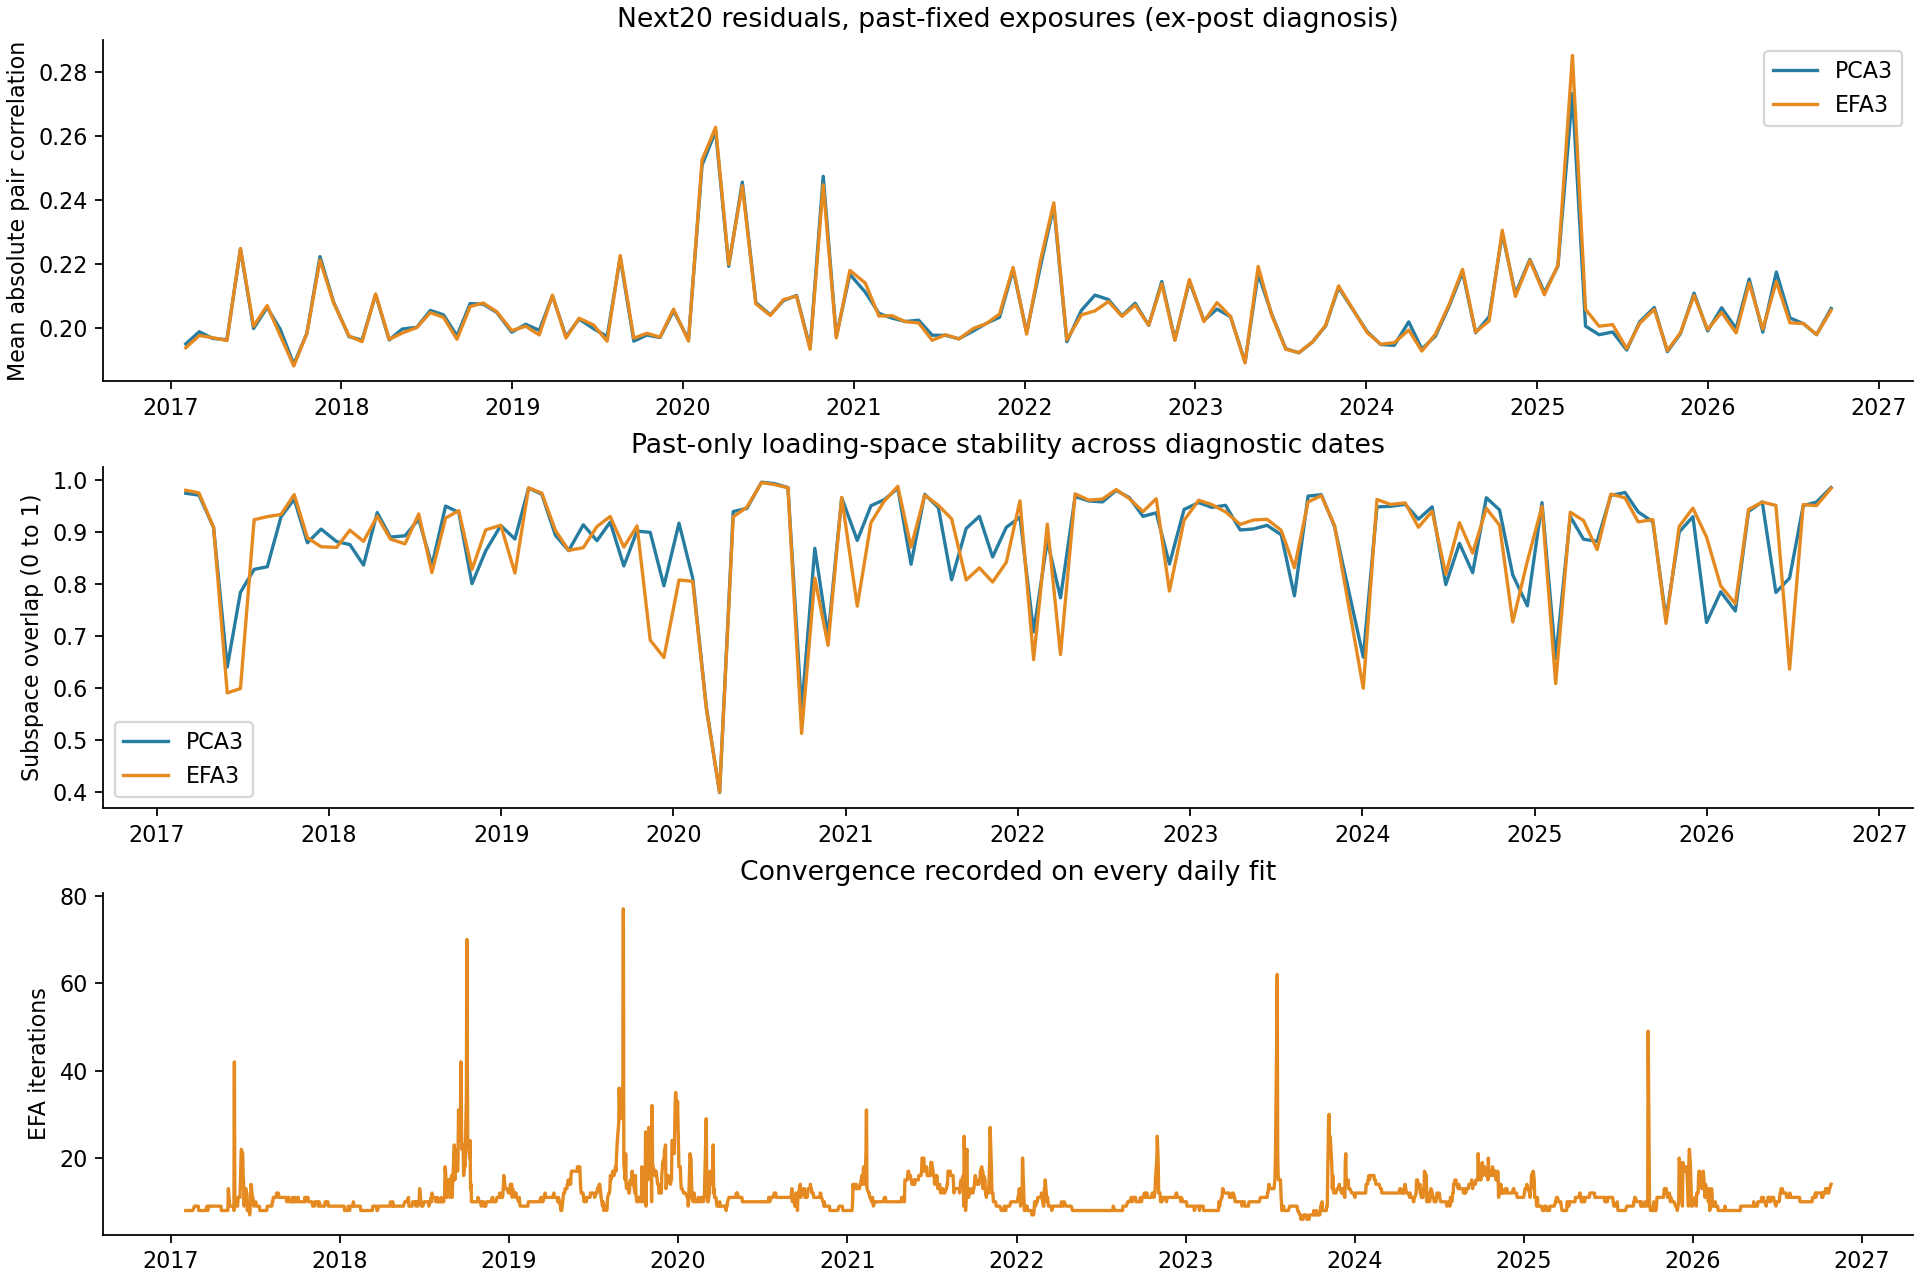

In [4]:
display(structural.round(6))
display(paired.loc[paired.metric.isin(["future_abs_corr","subspace_stability"]),
    ["period","metric","count","difference","sim95_low","sim95_high"]].round(6))
display(Image(filename=str(out/"02_paired_comparisons.png")))
display(Image(filename=str(out/"04_factor_diagnostics.png")))

## 4. Do the residual moves reverse over 1, 5, or 20 sessions?

These are frozen initial sleeves, not twenty overlapping funded portfolios. All horizons use the same complete twenty-session event dates: 1,719 earlier and 689 later. Entry/exit are adjusted open/close marks. This differs from the full raw daily execution calendar, including omission of nineteen later tail dates. A different one-day event mean is not a contradiction.

The response slope compares the current residual with subsequent stock returns using the same weights. **Negative means reversal direction; positive means continuation direction.** All standalone slope and event-mean intervals span zero in both periods.

EFA's later event means are +0.968, +0.236, and −2.946 bps for 1/5/20 sessions. Its twenty-session mean is less negative than PCA's. Some twenty-session paired pointwise intervals exclude zero, but the declared three-horizon simultaneous bands do not. EFA's own twenty-session mean remains negative. This does not establish profitable mean reversion.

,period,model,horizon,events,mean_event_bps,mean_low,mean_high,response_slope,slope_low,slope_high
0,development,PCA3,1,1719,-0.059653,-2.054046,1.978136,0.006645,-0.005684,0.018533
1,development,EFA3,1,1719,-0.107555,-2.161377,1.909957,0.007002,-0.005517,0.019392
2,development,PCA3,5,1719,0.503856,-3.339703,4.464186,0.002148,-0.017446,0.022155
3,development,EFA3,5,1719,0.320413,-3.517221,4.232714,0.003826,-0.017029,0.024387
4,development,PCA3,20,1719,2.790655,-2.143483,8.083827,-0.003891,-0.037538,0.033747
5,development,EFA3,20,1719,2.537894,-2.496943,7.867444,-0.001451,-0.037831,0.037876
6,later,PCA3,1,689,0.902937,-0.923287,2.593226,-0.005517,-0.014082,0.003770
7,later,EFA3,1,689,0.967752,-0.880575,2.609883,-0.005872,-0.014353,0.003617
8,later,PCA3,5,689,-0.027669,-4.218708,4.142484,-0.000758,-0.023457,0.019827
9,later,EFA3,5,689,0.236326,-4.025093,4.615895,-0.001932,-0.024293,0.018393


,period,metric,difference,point95_low,point95_high,sim95_low,sim95_high
1,development,event1_mean_bps,-0.047902,-0.125851,0.032034,-0.143840,0.048036
2,development,event5_mean_bps,-0.183443,-0.430314,0.035100,-0.470784,0.103899
3,development,event20_mean_bps,-0.252761,-0.842695,0.254278,-0.915547,0.410024
4,development,event1_slope,0.000358,-0.000231,0.000932,-0.000336,0.001051
5,development,event5_slope,0.001678,-0.000576,0.004516,-0.001475,0.004831
6,development,event20_slope,0.002440,-0.002374,0.007326,-0.003342,0.008222
10,later,event1_mean_bps,0.064815,-0.141700,0.252705,-0.162952,0.292583
11,later,event5_mean_bps,0.263995,-0.138278,0.689074,-0.220576,0.748566
12,later,event20_mean_bps,0.738481,0.133717,1.440264,-0.026572,1.503535
13,later,event1_slope,-0.000355,-0.001235,0.000602,-0.001452,0.000742


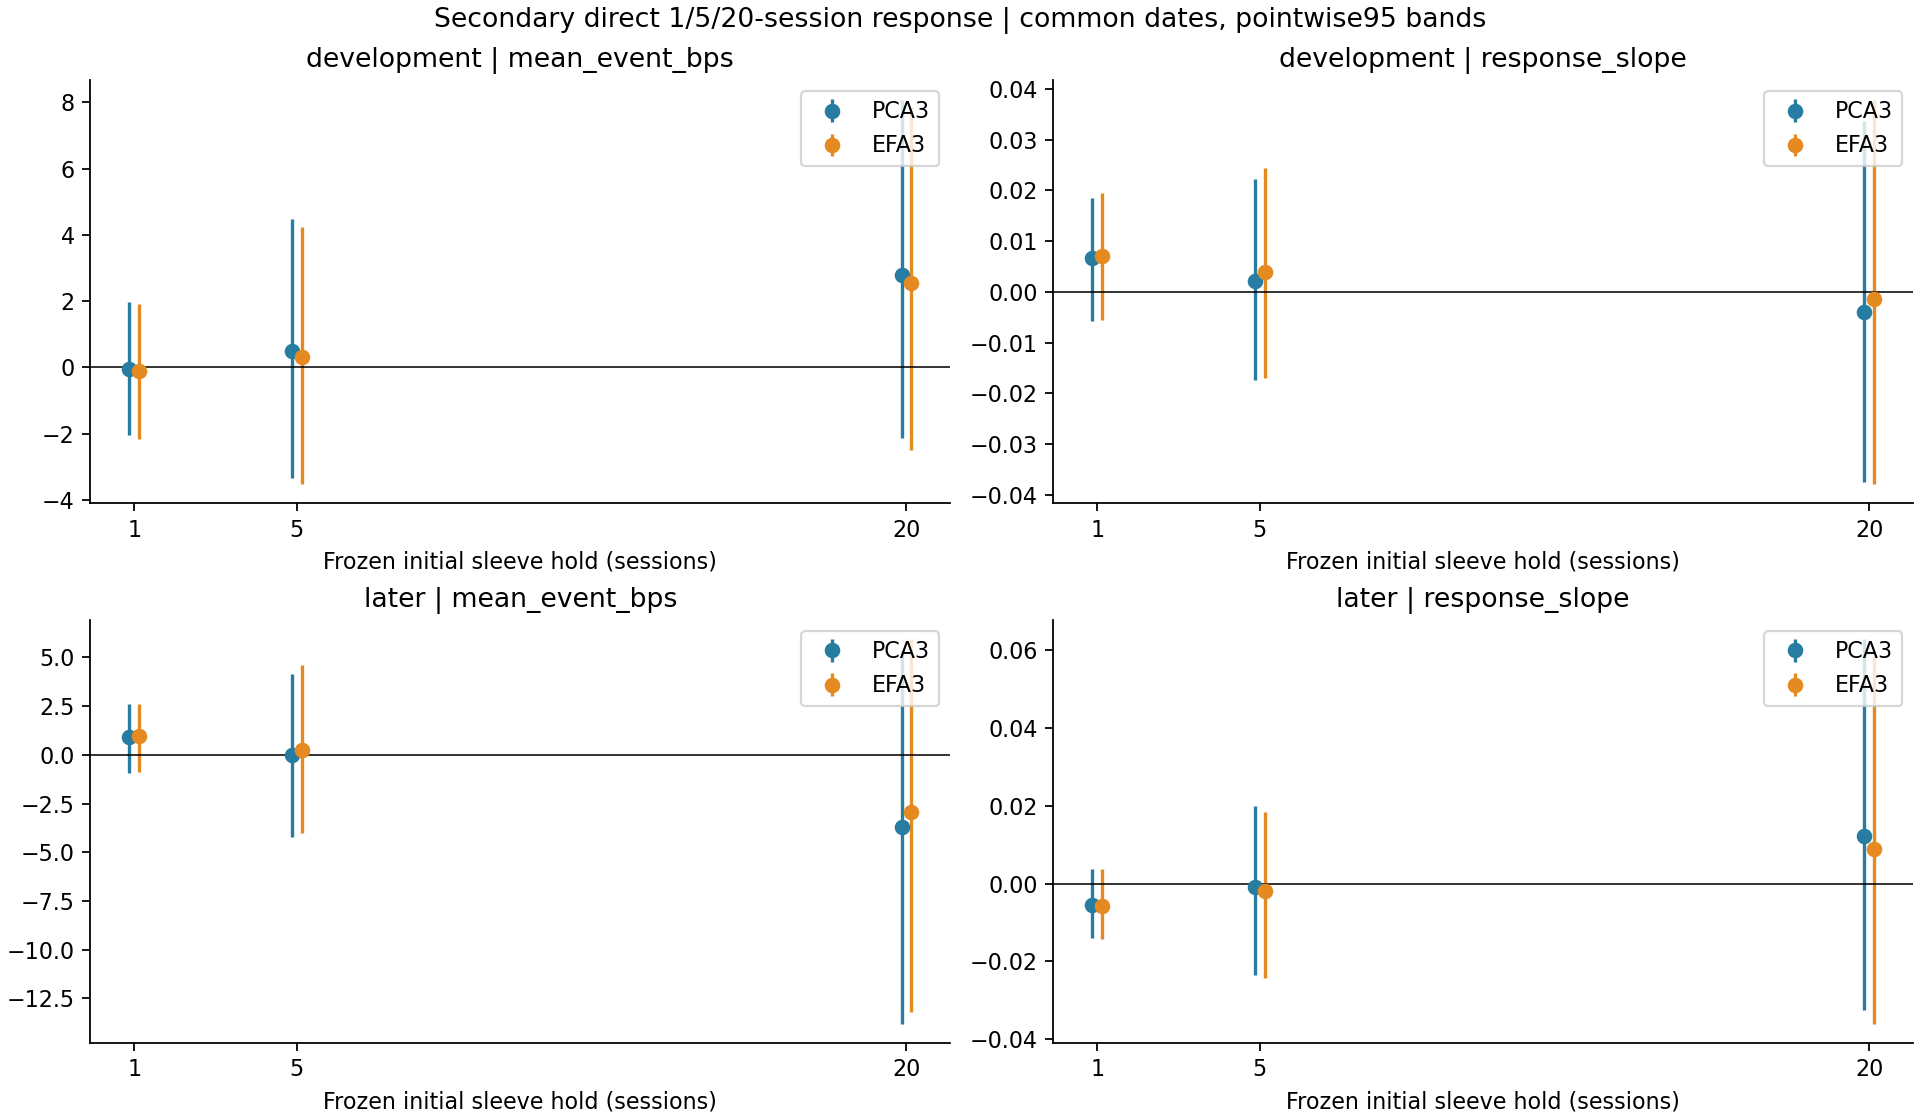

In [5]:
display(horizon.round(6))
display(paired.loc[paired.metric.str.startswith("event"),
    ["period","metric","difference","point95_low","point95_high","sim95_low","sim95_high"]].round(6))
display(Image(filename=str(out/"03_horizon_response.png")))

## 5. Checks and decision

All 2,446 EFA fits converged in 6–77 iterations. Their unique variances remain above the numerical floor. The independent audit reconstructs every portfolio and Gaussian training likelihood, refits thirteen windows, checks an independent EM update, and reconciles daily/event ledgers, future correlations, stability, metrics and uncertainty bands. The old PCA positions and results remain intact. These checks address implementation correctness, not a global optimum or the truth of the factor model.

The median later cross-method loading-space overlap is 0.970: the fitted three-dimensional spaces are usually closely aligned. That is consistent with a small implementation change; it does not give the factors an economic interpretation.

**Decision:** keep PCA as the existing baseline and EFA as a completed matched alternative. EFA does not materially alter the conclusion that short-term residual reversal is unconfirmed. No TDA gate, rotation/count search, or other experiment is inferred from the slightly higher later CAGR. The survivor universe, short rolling sample, already examined dates, fixed factor count, and noisy secondary diagnostics remain limitations.

In [6]:
for name, passed in audit["checks"].items():
    print(name,passed)
print("Daily formations independently checked:",audit["daily_formations_checked"])
print("Independent EFA refits:",audit["independent_EFA_refits"])
print("Maximum holding reconstruction difference:",audit["max_position_error"])
print("Maximum Gaussian loglikelihood difference:",audit["max_EFA_loglikelihood_error"])
assert all(audit["checks"].values())

all_daily_admission_and_training_dates_causal True
all_raw_scaled_loadings_and_WLS_positions_reconstructed True
all_EFA_training_loglikelihoods_match_Gaussian_model True
selected_EFA_refits_match_saved_covariance True
independent_EM_step_likelihood_nondecrease True
all_raw_and_adjusted_return_ledgers_reconcile True
all_future_residual_correlations_and_rotation_invariant_stabilities_match True
all_metrics_and_paired_bootstrap_intervals_reproduced True
protected_prior_artifacts_unchanged True
Daily formations independently checked: 2446
Independent EFA refits: 13
Maximum holding reconstruction difference: 2.1415161310933684e-15
Maximum Gaussian loglikelihood difference: 3.0398950912058353e-08
